# Lab 4

## Problem One (and only)



In [17]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import scipy
from scipy import stats
import h5py

hf = h5py.File('gammaray_lab4.h5', 'r')

hf.keys()

data = np.array(hf.get('data'))

print(np.shape(data))
print(data[:,0])

hf.close()


(4, 25920001)
[9.40680016e+08 3.15000000e+02 4.50000000e+01 1.00000000e+01]


In [2]:

data[0] = data[0] - data[0][0] # setting the start time to 0

print(data[0,:])
step = 10000
datastepped = data[:,::step] # getting every 10,000th data point to start

print(np.shape(datastepped))
print(datastepped[2])

[0.00000000e+00 1.00000024e-01 2.00000048e-01 ... 2.59199980e+06
 2.59199990e+06 2.59200000e+06]
(4, 2593)
[ 45.         111.66666667 178.33333333 ... 271.66666667 338.33333333
  45.        ]


## 1



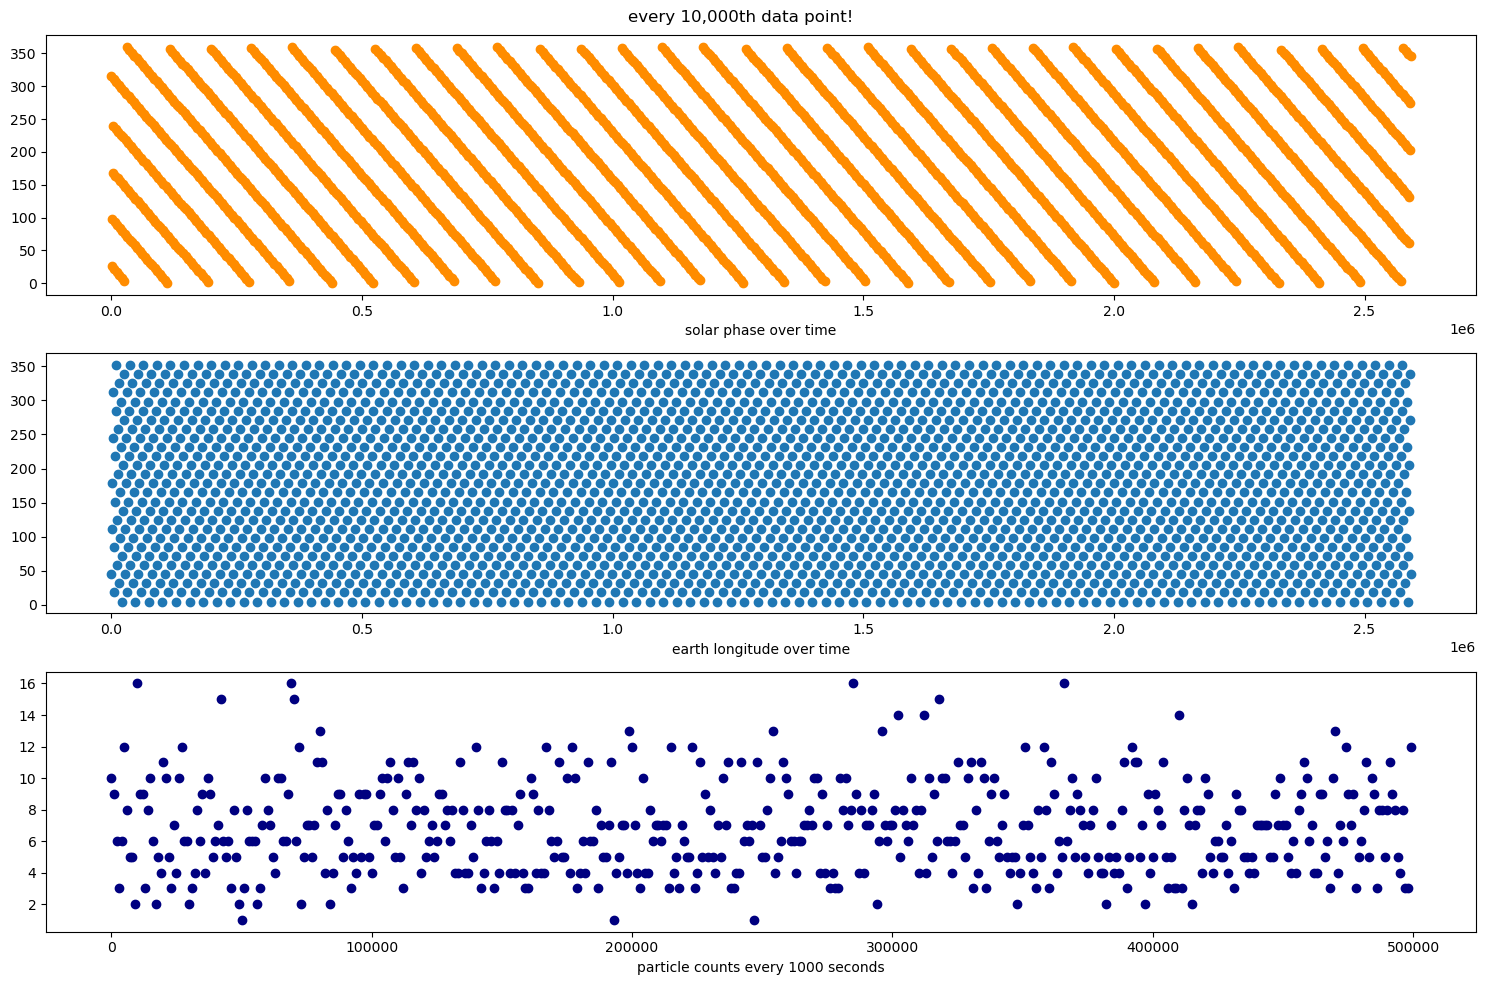

In [3]:
fig, ax = plt.subplots(3, figsize = (15,10))
ax[0].scatter(datastepped[0], datastepped[1], color = 'darkorange')
ax[0].set_xlabel('solar phase over time')
ax[1].scatter(datastepped[0], datastepped[2])
ax[1].set_xlabel('earth longitude over time')
ax[2].scatter(datastepped[0, :500], datastepped[3, :500], color = 'navy')
ax[2].set_xlabel('particle counts every 1000 seconds')
plt.suptitle('every 10,000th data point!')
plt.tight_layout()
plt.show()

This is just to get an idea of the shape of things over time. The first two are fantastically useless. Let's try an average!

In [4]:
avgstep = 90*600
avg = np.zeros((4, avgstep))
bins = int(np.floor(25920001 / avgstep))
print(bins)
for i in range(bins):
    avg += data[:, avgstep * i:avgstep * (i + 1)]
avg = avg / bins
avg[0] = data[0,:avgstep]
print(avg)

480
[[0.00000000e+00 1.00000024e-01 2.00000048e-01 ... 5.39970000e+03
  5.39980000e+03 5.39990000e+03]
 [1.79385069e+02 1.79392182e+02 1.79399294e+02 ... 1.79426927e+02
  1.79434039e+02 1.79441152e+02]
 [4.50000000e+01 4.50066667e+01 4.50133333e+01 ... 4.49800000e+01
  4.49866667e+01 4.49933333e+01]
 [7.72500000e+00 7.78541667e+00 7.86875000e+00 ... 7.57916667e+00
  7.64166667e+00 7.88333333e+00]]


Let's try those plots again.

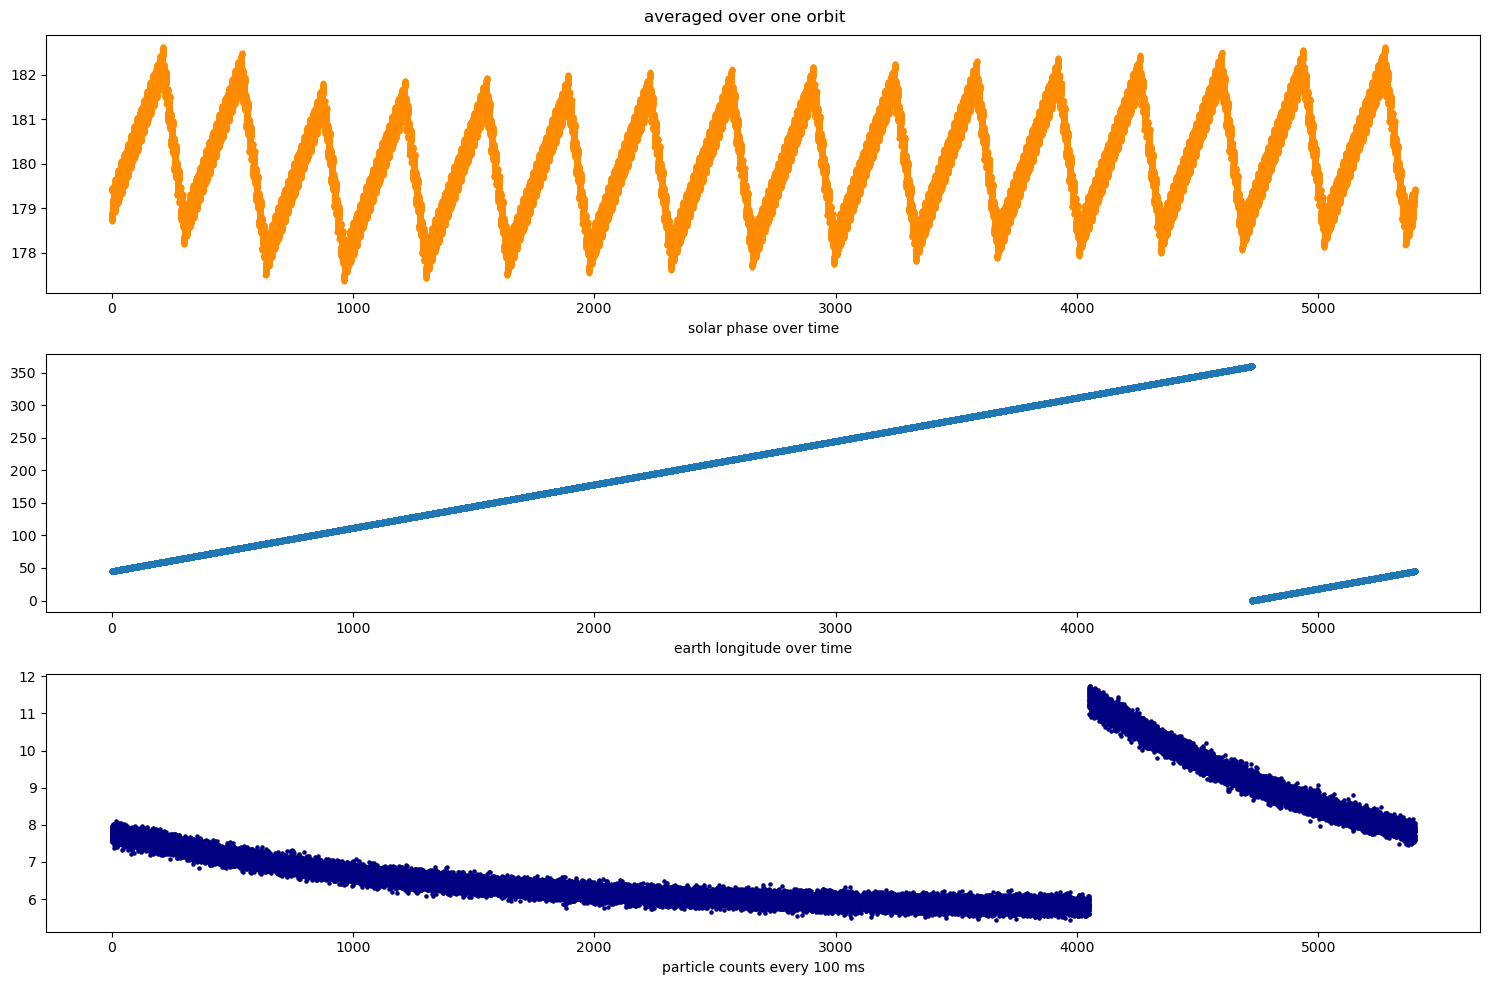

In [5]:
fig, ax = plt.subplots(3, figsize = (15, 10))
ax[0].scatter(avg[0], avg[1], color = 'darkorange', s = 10)
ax[0].set_xlabel('solar phase over time')
ax[1].scatter(avg[0], avg[2], s = 10)
ax[1].set_xlabel('earth longitude over time')
ax[2].scatter(avg[0], avg[3], color = 'navy', s = 5)
ax[2].set_xlabel('particle counts every 100 ms')
plt.suptitle('averaged over one orbit')
plt.tight_layout()
plt.show()

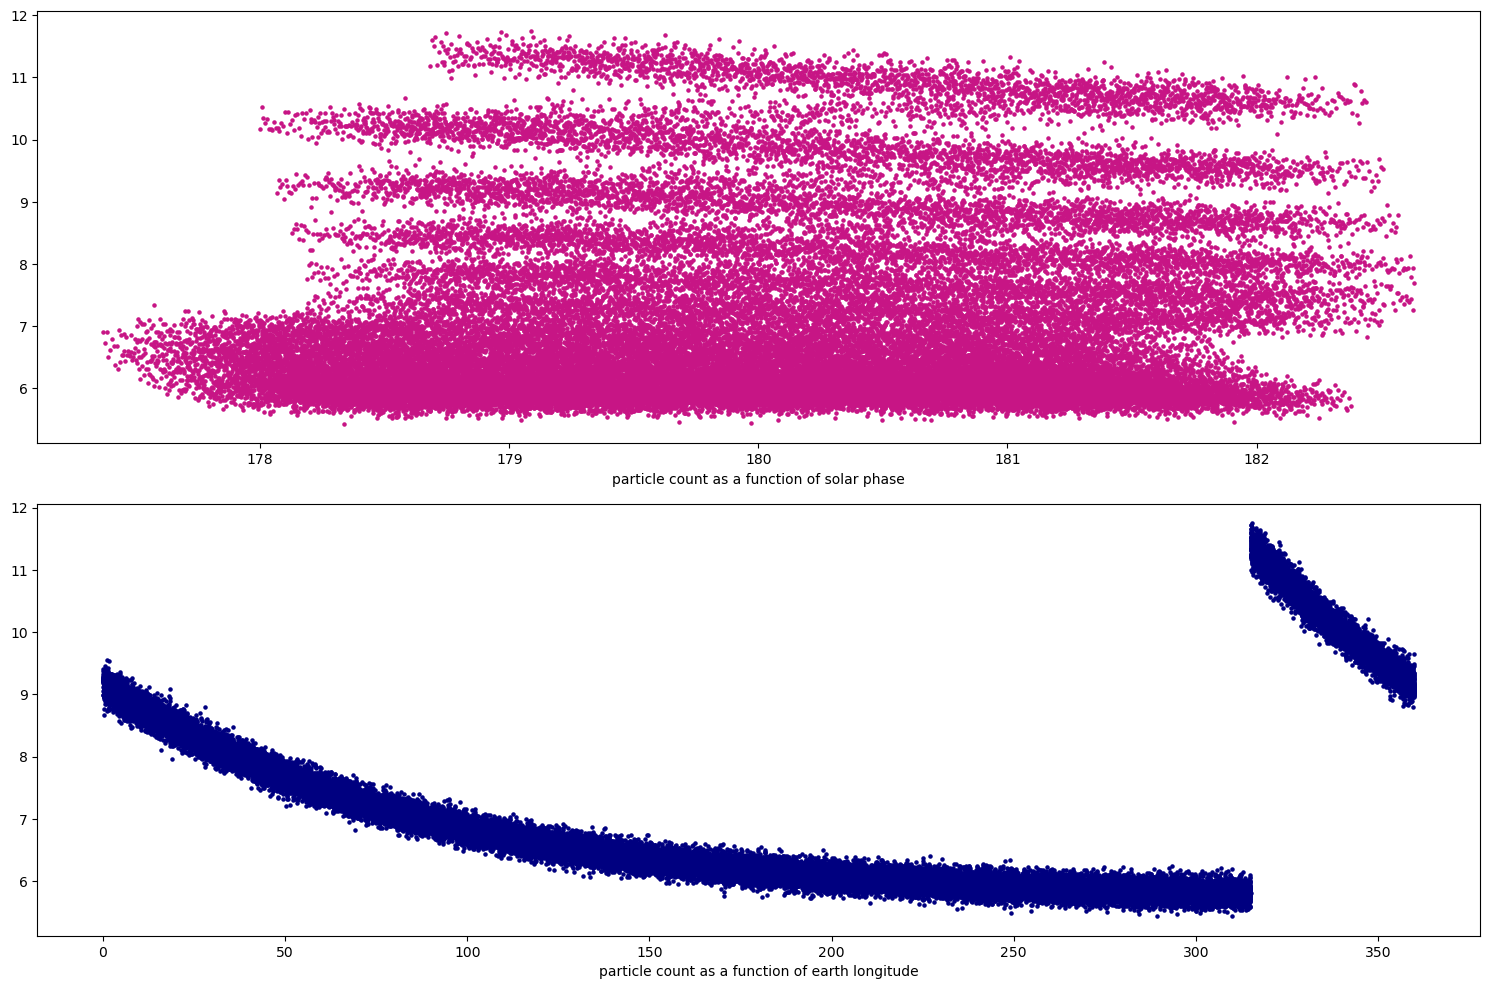

In [6]:
fig, ax = plt.subplots(2, figsize = (15, 10))
ax[0].scatter(avg[1], avg[3], color = 'mediumvioletred', s = 5)
ax[0].set_xlabel('particle count as a function of solar phase')
ax[1].scatter(avg[2], avg[3], color = 'navy', s = 5)
ax[1].set_xlabel('particle count as a function of earth longitude')
plt.tight_layout()
plt.show()

Hmmm, the solar phase *seems* irrelevant but the earth longitude seems to correlate a lot. Not what I expected!

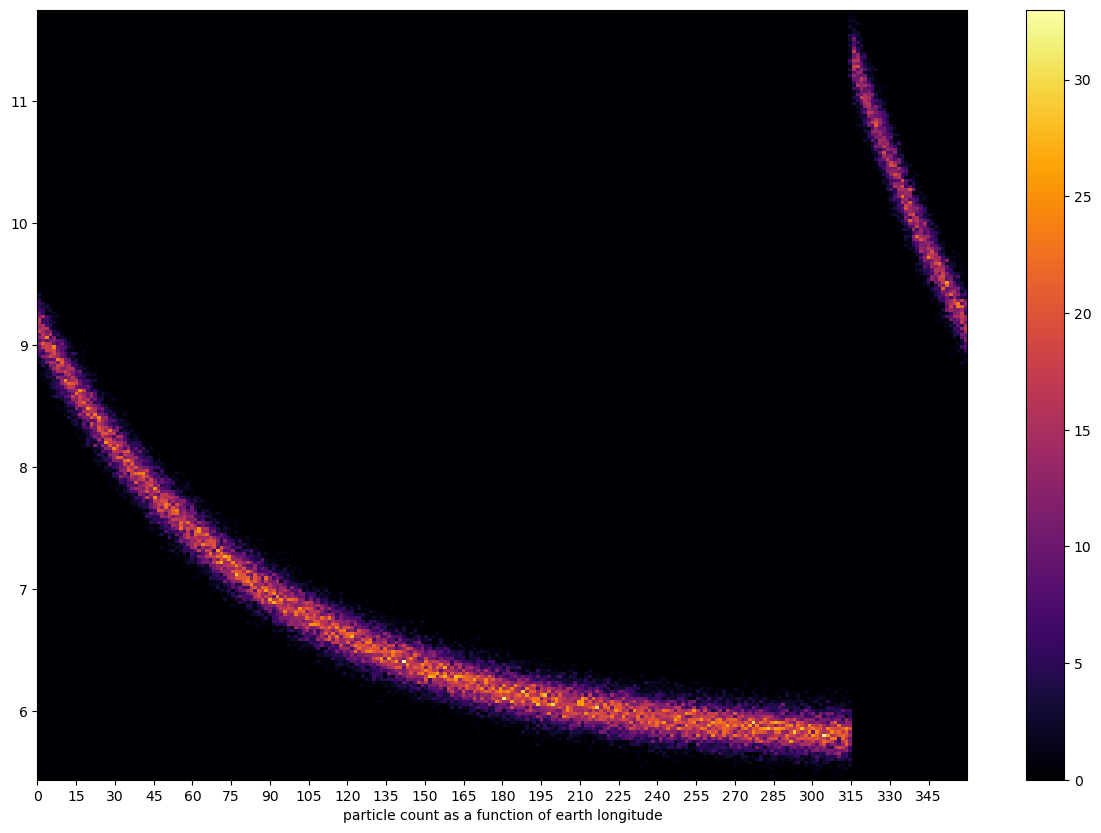

In [7]:
'''plt.figure(figsize = (15,10))
plt.hist2d(avg[1], avg[3], 250, cmap = 'inferno')
plt.xlabel('particle count as a function of solar phase')
plt.colorbar()
plt.show()'''
ticks = np.arange(0, 360, 15)
plt.figure(figsize = (15,10))
plt.hist2d(avg[2], avg[3], 250, cmap = 'inferno')
plt.xlabel('particle count as a function of earth longitude')
plt.xticks(ticks)
plt.colorbar()
plt.show()

Interesting. Certainly a surprising discontinuity at ~315 degrees. This seems like the most pertinent relationship so I will focus on this. One more plot real quick to check the first couple days.


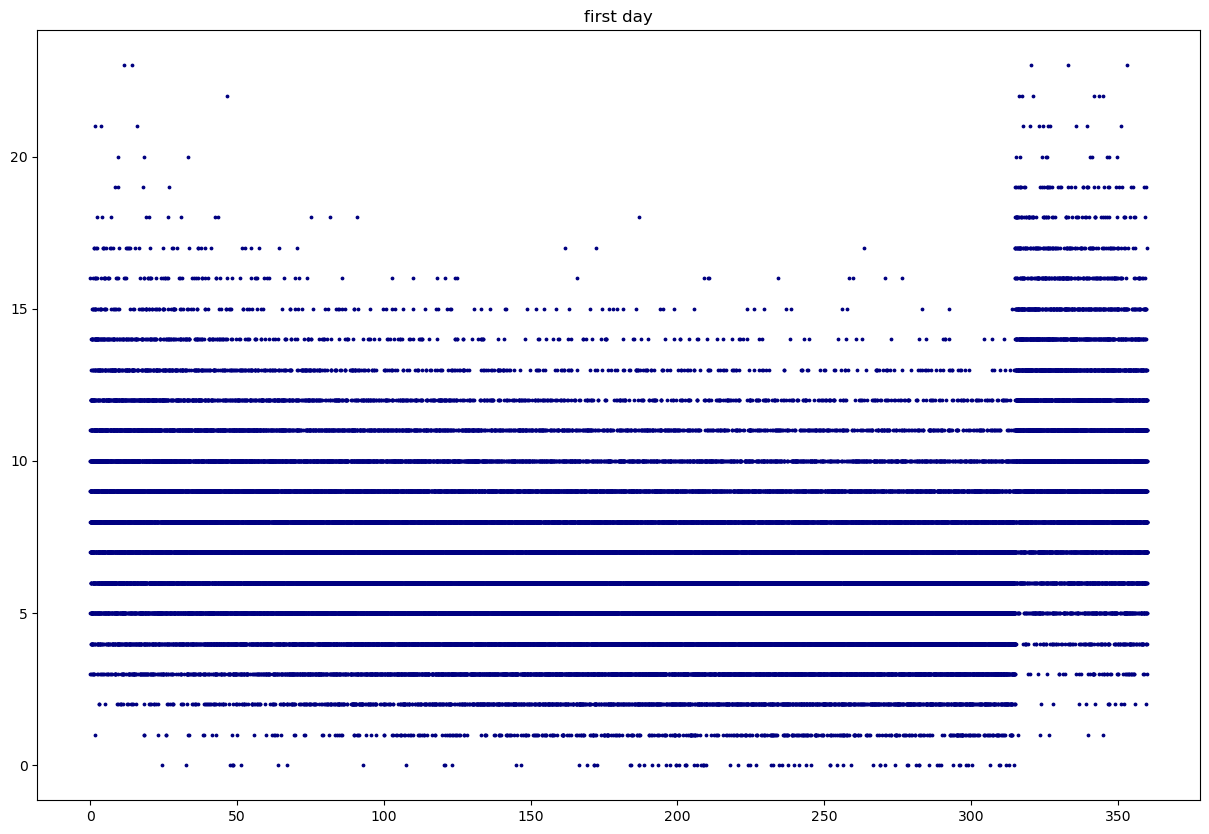

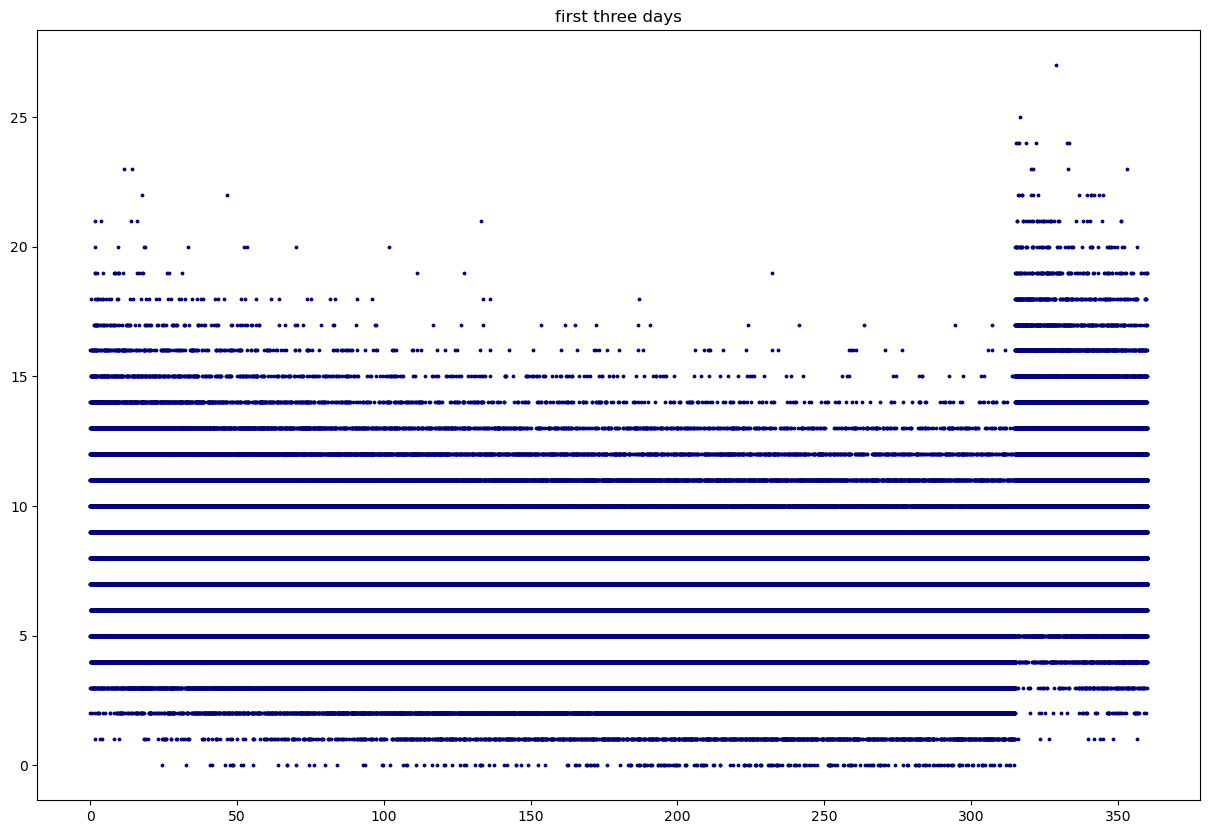

In [8]:
plt.figure(figsize = (15,10))
plt.scatter(data[2, :54000], data[3, :54000], s = 3, color = 'navy')
plt.title('first day')
plt.show()
plt.figure(figsize = (15,10))
plt.scatter(data[2, :54000*3], data[3, :54000*3], s = 3, color = 'navy')
plt.title('first three days')
plt.show()

That same discontinuity is visible at ~315 degrees! Looks like we're on the right track.

I am unsure about signal contamination right now. My plan for background pdf is to use a Poisson distribution with the first ten orbits, not the average.

## 2

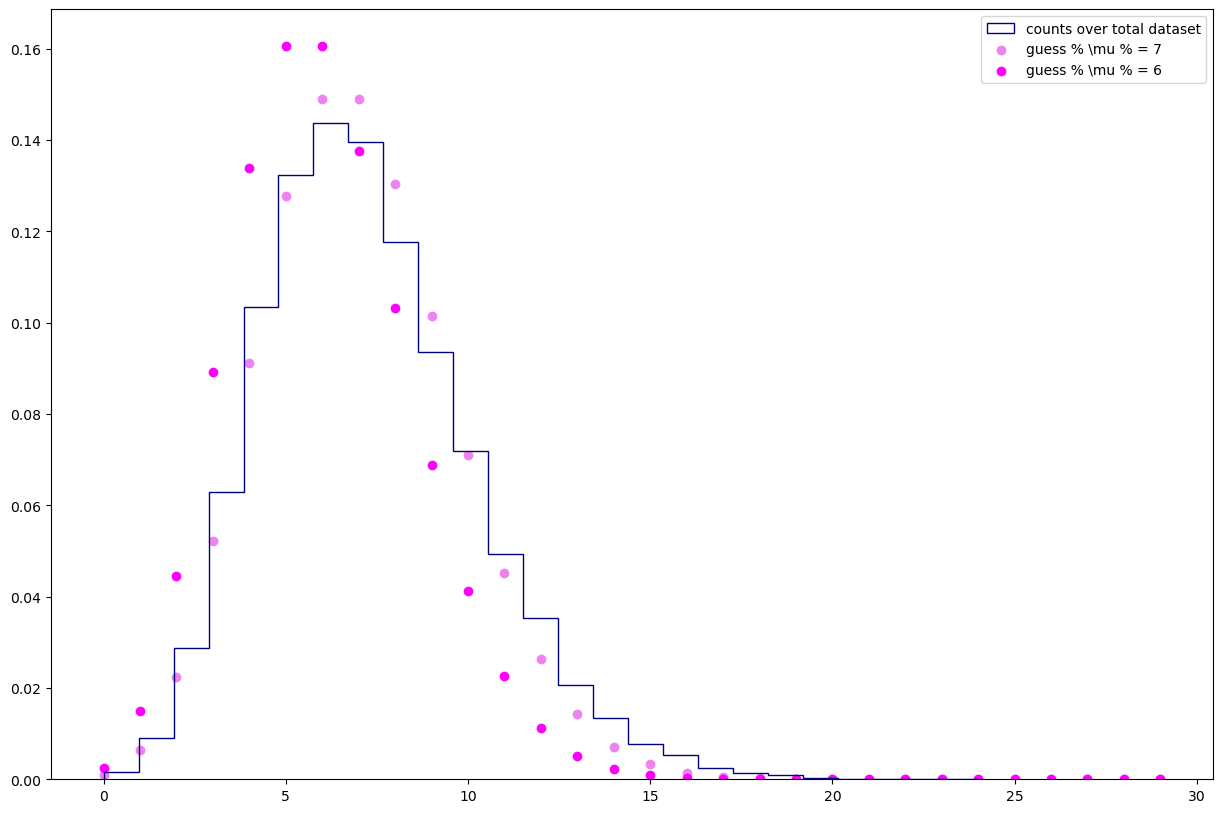

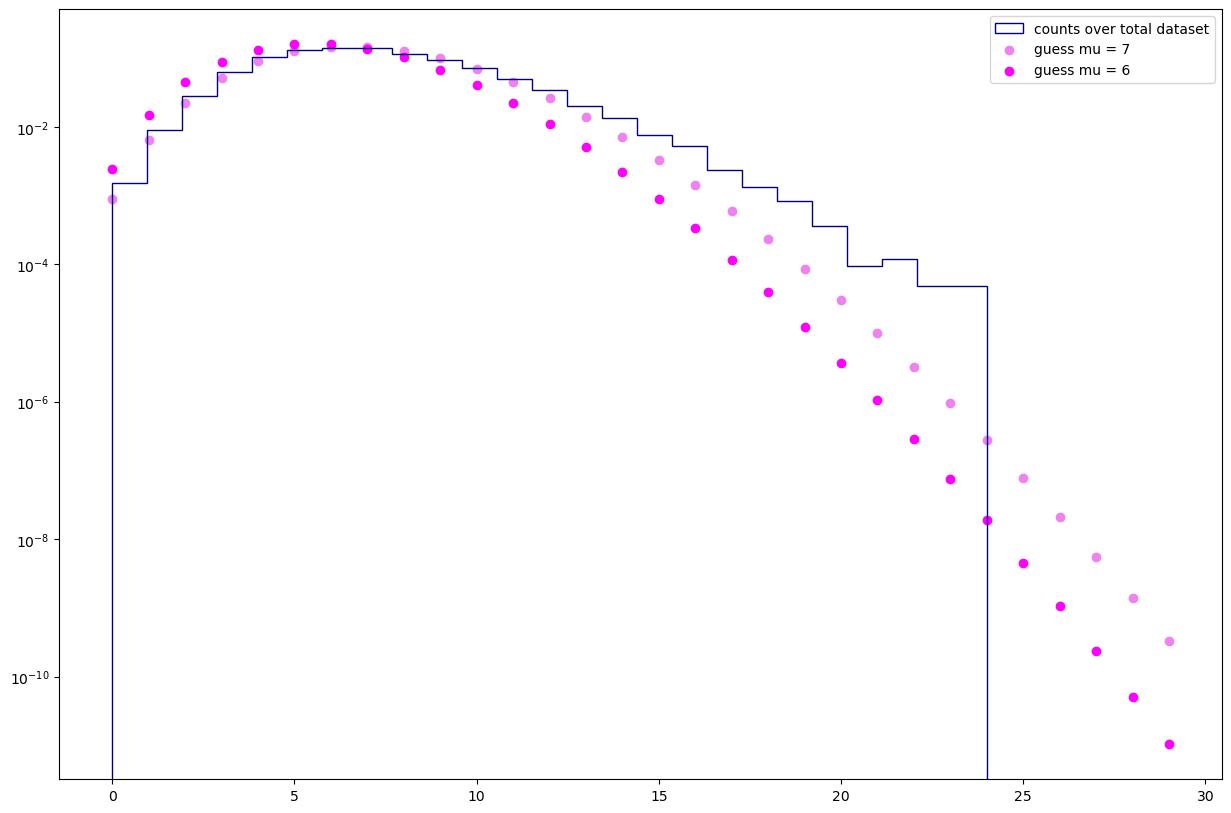

In [14]:
plt.figure(figsize = (15,10))
plt.hist(data[3, ::600], 25, color = 'navy', density = True, histtype = 'step', label = 'counts over total dataset')

mu = 7
x = np.arange(data[3].min(), data[3].max())
plt.scatter(x, stats.poisson.pmf(x, mu), color = 'violet', label = r'guess % \mu % = 7')
mu = 6
x = np.arange(data[3].min(), data[3].max())
plt.scatter(x, stats.poisson.pmf(x, mu), color = 'magenta', label = r'guess % \mu % = 6')
plt.legend()
plt.show()

plt.figure(figsize = (15,10))
plt.hist(data[3, ::600], 25, color = 'navy', density = True, histtype = 'step', label = 'counts over total dataset')

mu = 7
x = np.arange(data[3].min(), data[3].max())
plt.scatter(x, stats.poisson.pmf(x, mu), color = 'violet', label = r'guess mu = 7')
mu = 6
x = np.arange(data[3].min(), data[3].max())
plt.scatter(x, stats.poisson.pmf(x, mu), color = 'magenta', label = r'guess mu = 6')
plt.yscale('log')
plt.legend()
plt.show()

The tail of our data looks a little denser than our Poisson. This is the whole dataset though. Let's see if things change over several days.

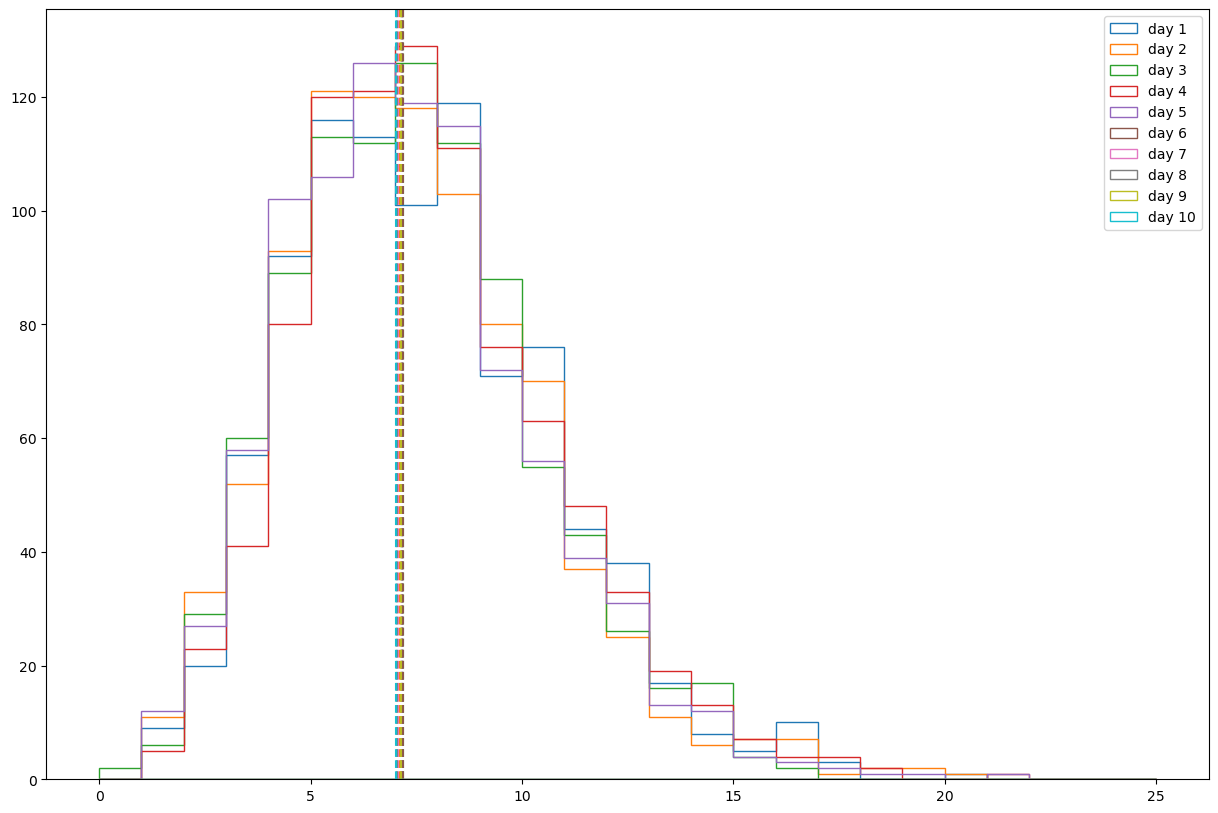

In [52]:
plt.figure(figsize = (15,10))
colors = list(mcolors.TABLEAU_COLORS)
for i in range(10):
    plt.hist(data[3, i*(54000*100):((i)*(54000*100) + 540000):600], bins = np.arange(0, 26, 1), color = colors[i], histtype = 'step', label = f'day {i + 1}')
    plt.axvline(np.mean(data[3, i*(60*600*24):(i + 1)*(60*600*24):600]), color = colors[i], linestyle = '--')
plt.legend()
plt.show()

Okay ...

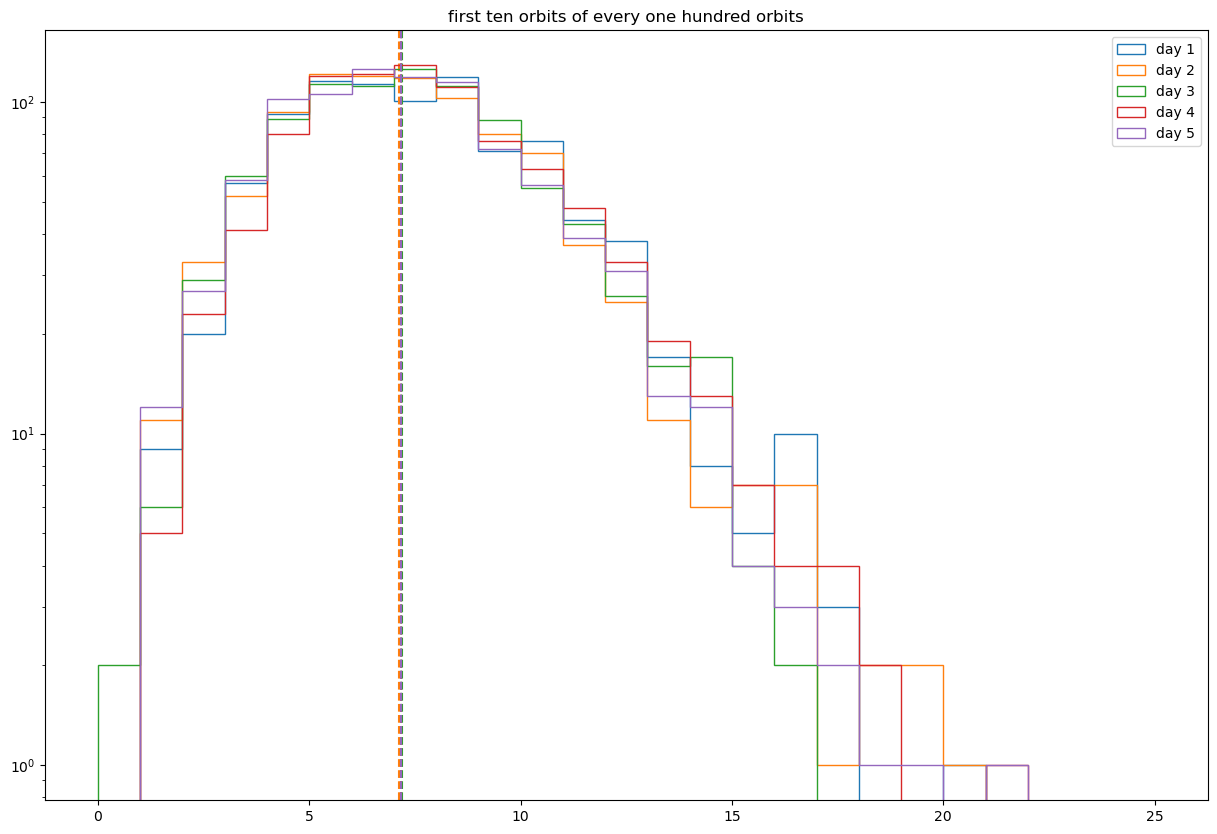

In [51]:
plt.figure(figsize = (15,10))
colors = list(mcolors.TABLEAU_COLORS)
for i in range(5): # the first 10 orbits of every 100 orbits
    plt.hist(data[3, i*(54000*100):((i)*(54000*100) + 540000):600], bins = np.arange(0, 26, 1), color = colors[i % 10], histtype = 'step', label = f'day {i + 1}')
    plt.axvline(np.mean(data[3, i*(60*600*24):(i + 1)*(60*600*24):600]), color = colors[i % 10], linestyle = '--')
plt.legend()
plt.yscale('log')
plt.title('first ten orbits of every one hundred orbits')
plt.show()



The means don't really move, but the tails are definitely moving to the right. Time to think about longitude ...

In [58]:
print(data[3][(data[2] >= 0) & (data[2] <= 2)]) #nice, i can do it like this

[ 3. 10.  5. ... 12.  5.  8.]


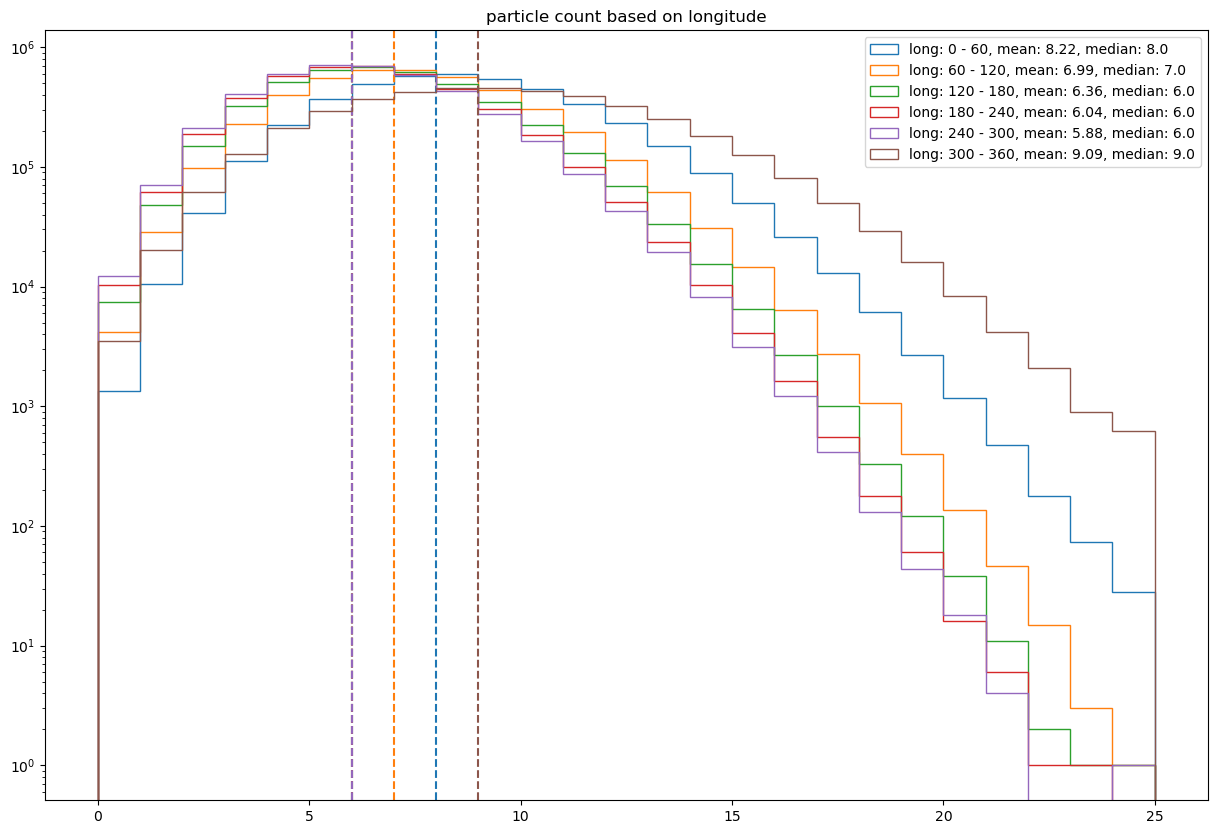

In [77]:
plt.figure(figsize = (15,10))
orbstep = 60
for i in range(6):
    plt.hist(data[3][(data[2] >= (i * orbstep)) & (data[2] <= (i * orbstep + orbstep))], bins = np.arange(0, 26, 1), color = colors[i % 10], histtype = 'step',
             label = f'long: {orbstep * i} - {orbstep * i + orbstep}, mean: {np.mean(data[3][(data[2] >= (i * orbstep)) & (data[2] <= (i * orbstep + orbstep))]):.2f}, median: {np.median(data[3][(data[2] >= (i * orbstep)) & (data[2] <= (i * orbstep + orbstep))])}')
    plt.axvline(np.median(data[3][(data[2] >= (i * orbstep)) & (data[2] <= (i * orbstep + orbstep))]), color = colors[i % 10], linestyle = '--')
plt.legend()
plt.yscale('log')
plt.title('particle count based on longitude')
plt.show()

Excellent, we can totally see the right tail of the distribution widening. This matches up with my 2D histogram from earlier.

In [118]:
def earthlong(a, b):
    a = a % 360
    b = b % 360
    return data[3][(data[2] >= a) & (data[2] <= b)]
orbit = 54000
orbstep = 10
steps = 360 / orbstep
print(earthlong(0, orbstep))
dist = np.array([])
for i in range(int(steps)):
    subset = earthlong(i * orbstep, (i + 1) * orbstep)
    mu = np.mean(subset)
    dist = np.append(dist, stats.poisson.rvs(mu, size = len(subset)))
print(dist)

[ 3. 10.  5. ...  9.  2.  9.]


ValueError: Domain error in arguments. The `scale` parameter must be positive for all distributions, and many distributions have restrictions on shape parameters. Please see the `scipy.stats.poisson` documentation for details.

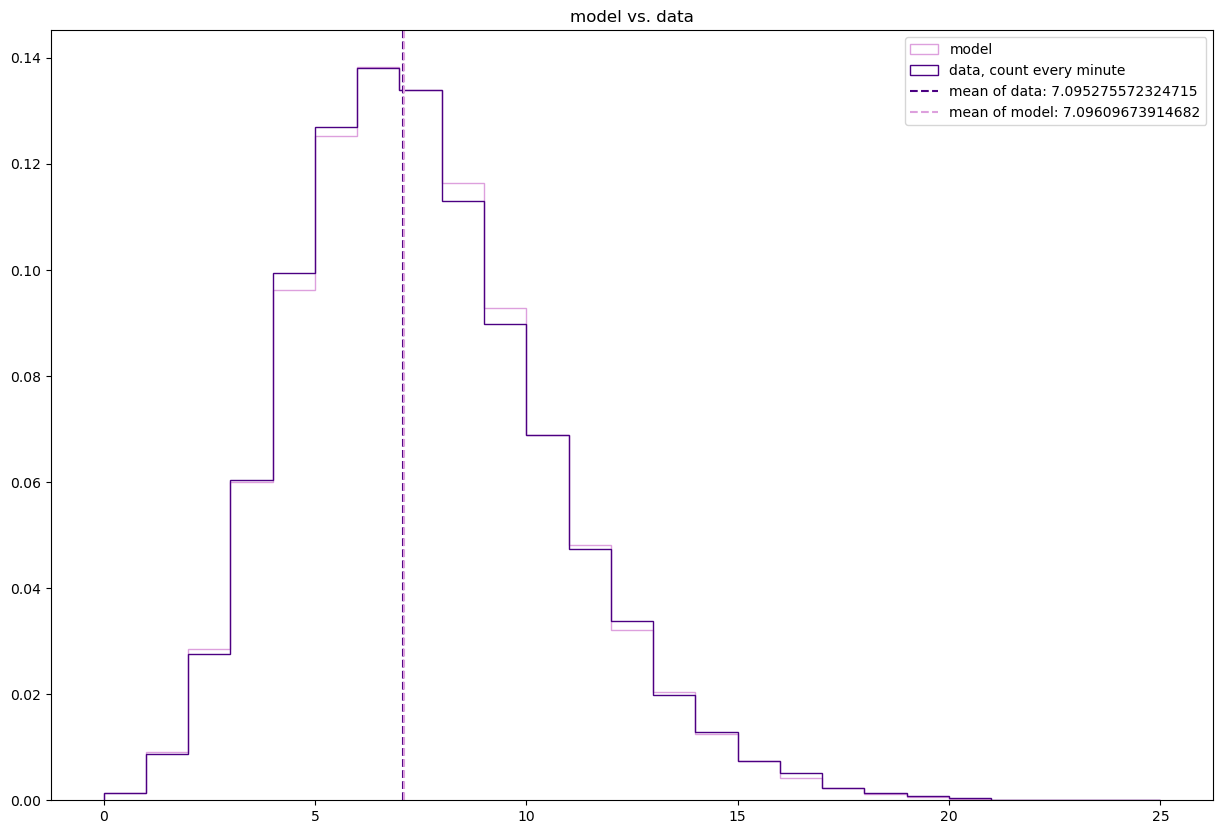

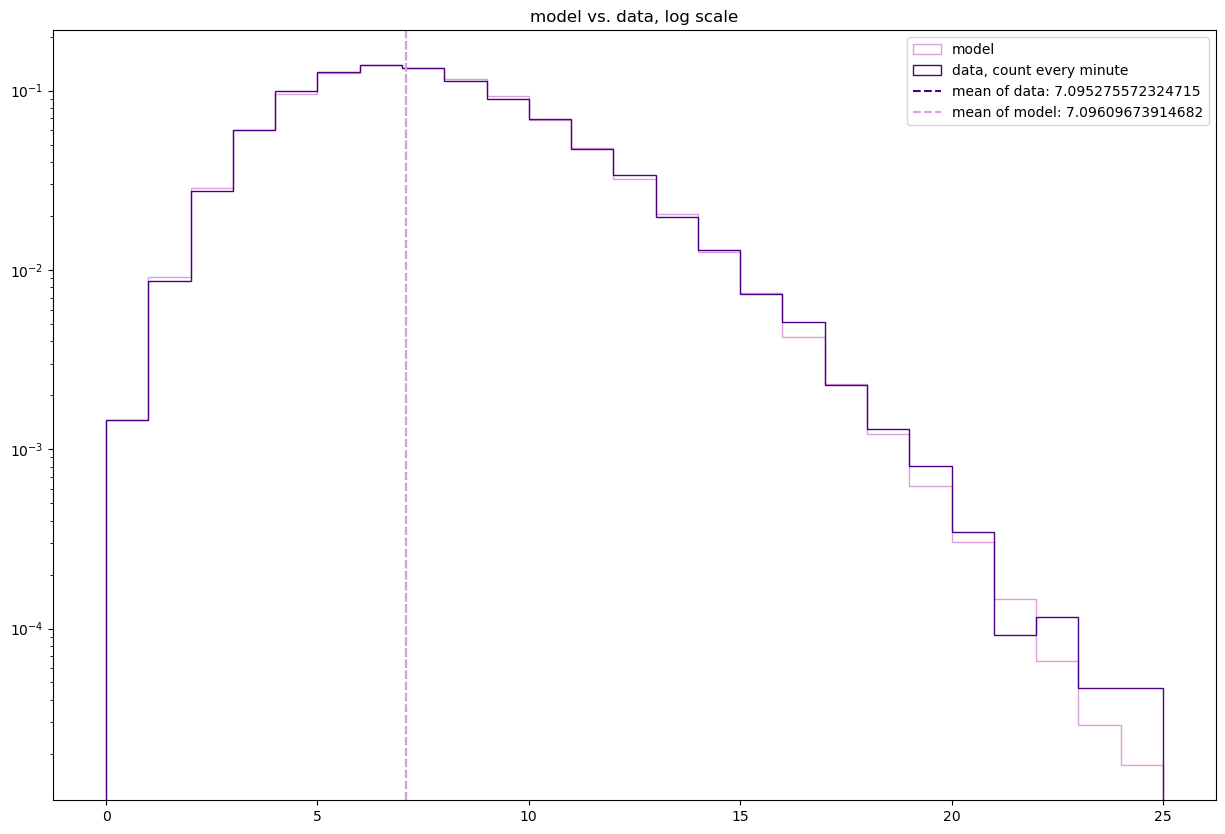

In [109]:
plt.figure(figsize = (15,10))
plt.title('model vs. data')
plt.hist(dist, bins = np.arange(0, 26), label = 'model', color = 'plum', histtype = 'step', density = True)
plt.hist(data[3, ::600], bins = np.arange(0,26), label = 'data, count every minute', color = 'indigo', histtype = 'step', density = True)
plt.axvline(np.mean(data[3, ::600]), label = f'mean of data: {np.mean(data[3, ::600])}', color = 'indigo', linestyle = '--')
plt.axvline(np.mean(dist), label = f'mean of model: {np.mean(dist)}', color = 'plum', linestyle = '--')
plt.legend()
plt.show()

plt.figure(figsize = (15,10))
plt.title('model vs. data, log scale')
plt.hist(dist, bins = np.arange(0, 26), label = 'model', color = 'plum', histtype = 'step', density = True)
plt.hist(data[3, ::600], bins = np.arange(0,26), label = 'data, count every minute', color = 'indigo', histtype = 'step', density = True)
plt.axvline(np.mean(data[3, ::600]), label = f'mean of data: {np.mean(data[3, ::600])}', color = 'indigo', linestyle = '--')
plt.axvline(np.mean(dist), label = f'mean of model: {np.mean(dist)}', color = 'plum', linestyle = '--')
plt.yscale('log')
plt.legend()
plt.show()

That is pretty close. It's off a little but not much. Let's plot the means of each of the individual bits of the model.

In [115]:
x_lon = np.arange(0, 361)
x_lon2 = np.arange(.5, 361)
means = np.array([])
for i in range(len(x_lon)):
    mean = np.mean(earthlong(i, i + 1))
    means = np.append(means, mean)
print(means)

[ 9.14028698  9.10289735  9.051766    9.02377208  8.99101821  8.95085541
  8.91164459  8.86554912  8.84751656  8.81060982  8.78025662  8.73715508
  8.71272075  8.67113687  8.65451159  8.61387969  8.58463024  8.5531043
  8.50571192  8.48896247  8.46078918  8.43609272  8.39828918  8.36287252
  8.33078091  8.29993102  8.29010762  8.22512417  8.22868377  8.19619205
  8.14481236  8.13686534  8.09816501  8.08672737  8.05814018  8.03067053
  7.98417494  7.98577539  7.95344923  7.9343681   7.9299255   7.87981512
  7.85361479  7.83520971  7.8019343   7.77561016  7.76245861  7.73022903
  7.70724338  7.69947572  7.66495585  7.65865066  7.63817605  7.61779801
  7.59184603  7.55989238  7.57057119  7.51699779  7.50968543  7.49384658
  7.47210265  7.45387693  7.41875     7.41316225  7.39627483  7.37553808
  7.35682947  7.31764625  7.31103753  7.28166391  7.27221302  7.25910596
  7.24071468  7.23352649  7.20405629  7.17760762  7.15985099  7.15854029
  7.13447848  7.11702539  7.1129415   7.09628863  7.

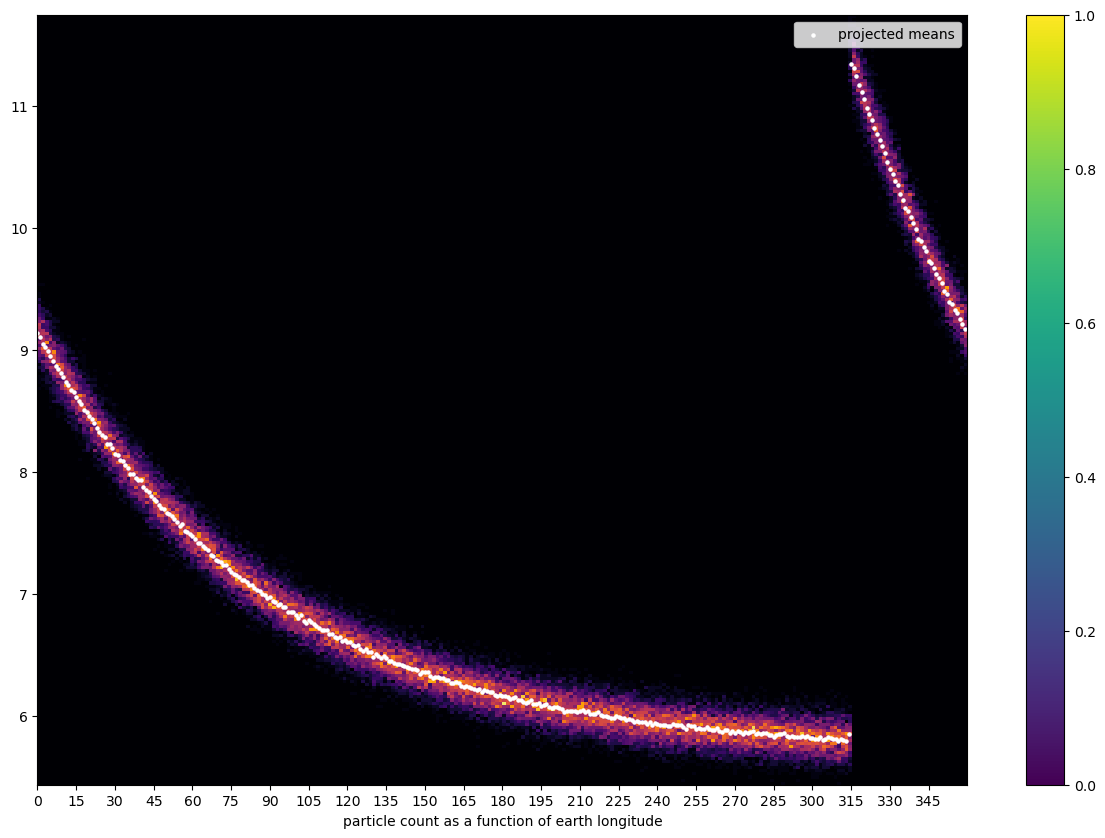

In [117]:
ticks = np.arange(0, 360, 15)
plt.figure(figsize = (15,10))
plt.hist2d(avg[2], avg[3], 250, cmap = 'inferno')
plt.xlabel('particle count as a function of earth longitude')
plt.xticks(ticks)
plt.scatter(x_lon, means, label = 'projected means', color = 'white', s = 5)
plt.colorbar()
plt.legend()
plt.show()

Well, well, well. That looks pretty stinkin' good.

## 4

In [ ]:
def getmean(a, b):
    return np.mean(earthlong(a, b))

def fivesigma(long):
    a = long - .5
    b = long + .5
    surv = stats.poisson.sf
    